# 01 · 1-NN baseline

使用老师指定的两个 trial，复现欧氏距离 1-NN 基线。先运行本 notebook 查看数据方向、类别分布和划分，再运行另外两个方法。代码只读取原始 zip，不修改数据。

**评估规则：**每个 trial 独立拟合；本方法没有调参，也没有逐 epoch 的 loss。老师给出的准确率是 91.35%、91.85%，均值 91.60%。

In [1]:
import time
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.neighbors import KNeighborsClassifier

from data_utils import load_data, get_trial, output_folder
from plot_utils import plot_data_overview
from evaluation import save_json, evaluate_predictions, save_method_summary, compare_methods

## 1. 读取和检查数据
MATLAB 图像按列展开，索引从 1 开始；公共函数已经统一恢复为 `[N, 28, 28]`、`[0,1]` 浮点图像和从 0 开始的索引。

In [2]:
data = load_data()
print("Images:", data["images"].shape, "Labels:", data["labels"].shape)
print("Pixel range:", data["images"].min(), data["images"].max())
display(pd.DataFrame({"digit": np.arange(10), "images": np.bincount(data["labels"])}))

Images: (4000, 28, 28) Labels: (4000,)
Pixel range: 0.0 1.0


,digit,images
0,0,400
1,1,400
2,2,400
3,3,400
4,4,400
5,5,400
6,6,400
7,7,400
8,8,400
9,9,400


## 2. 数据可视化
样例和像素分布使用 Trial 1 的训练集。图自动保存为 PNG 和 PDF。

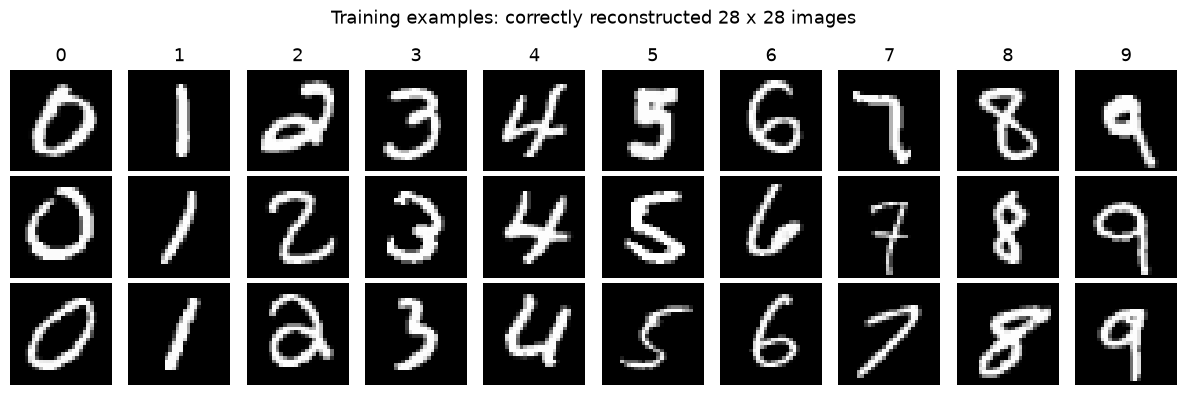

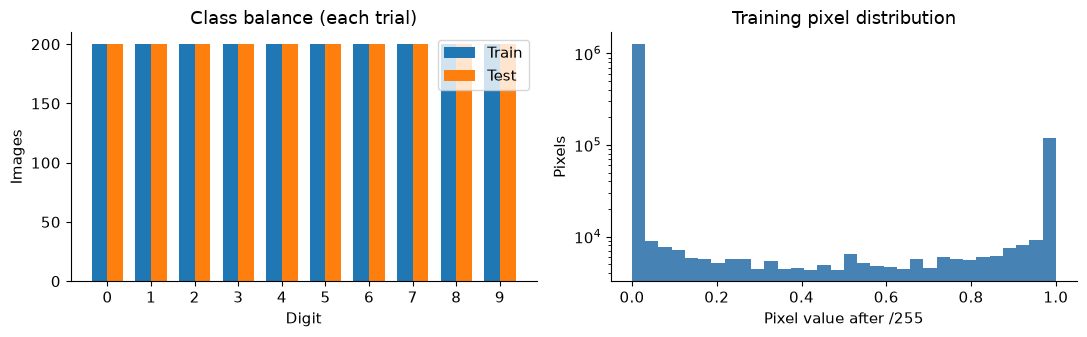

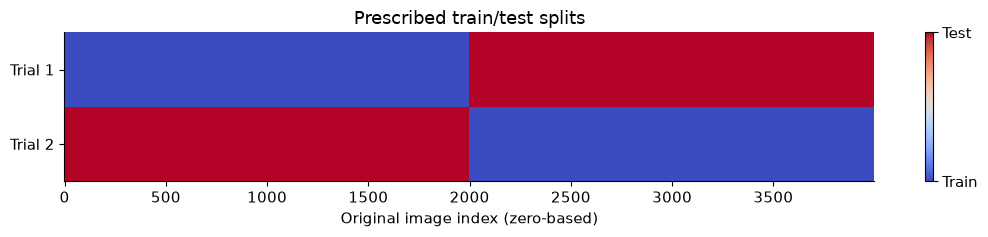

In [3]:
plot_data_overview(data, output_folder('data'))

## 3. 训练和评估
每组在全部 2,000 张训练图像上拟合，测试集仅用于最终预测与评估。

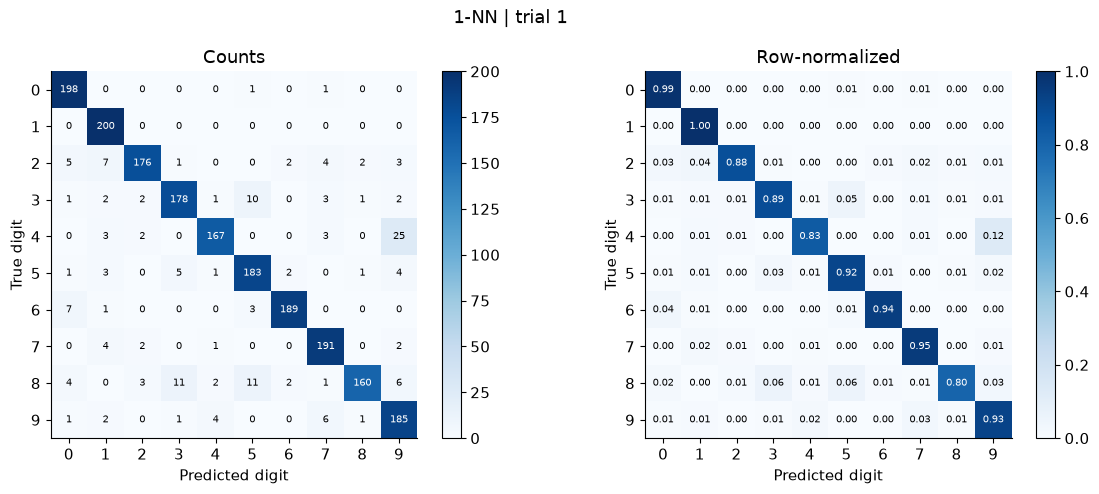

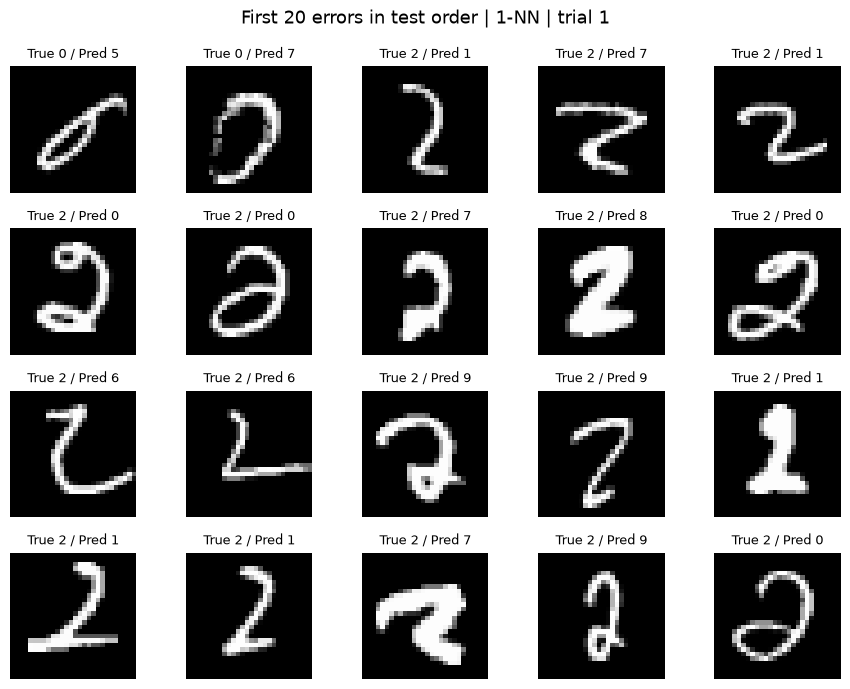

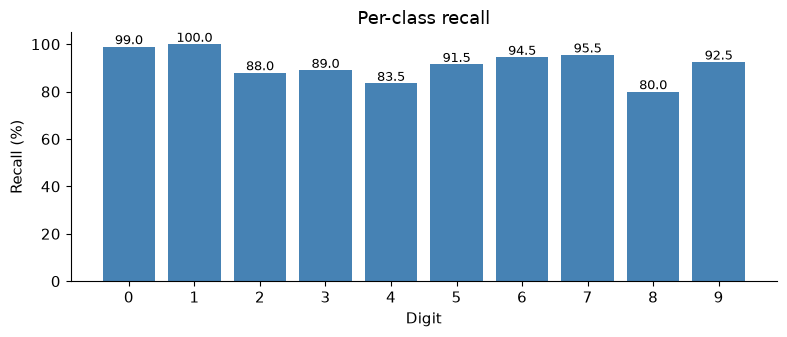

1-NN trial 1 accuracy = 0.9135


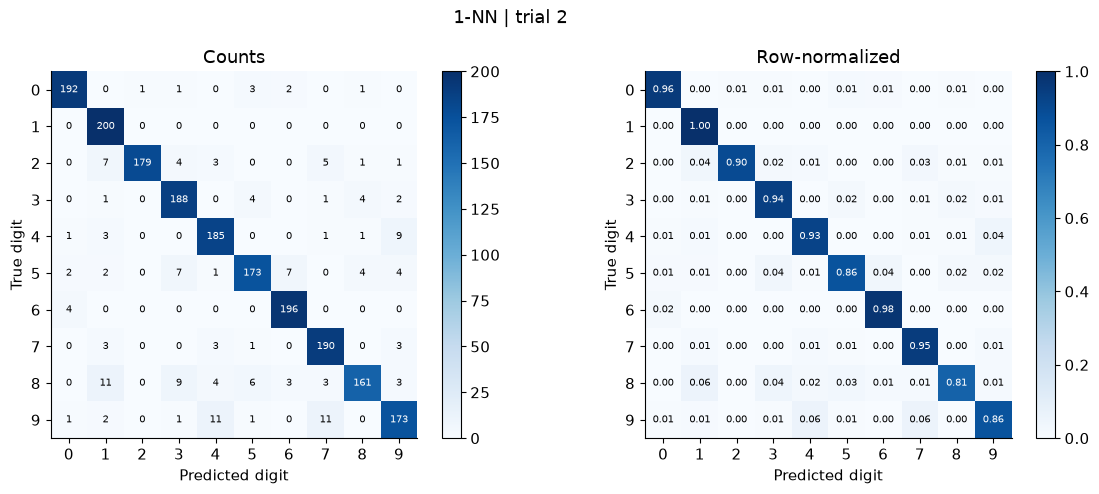

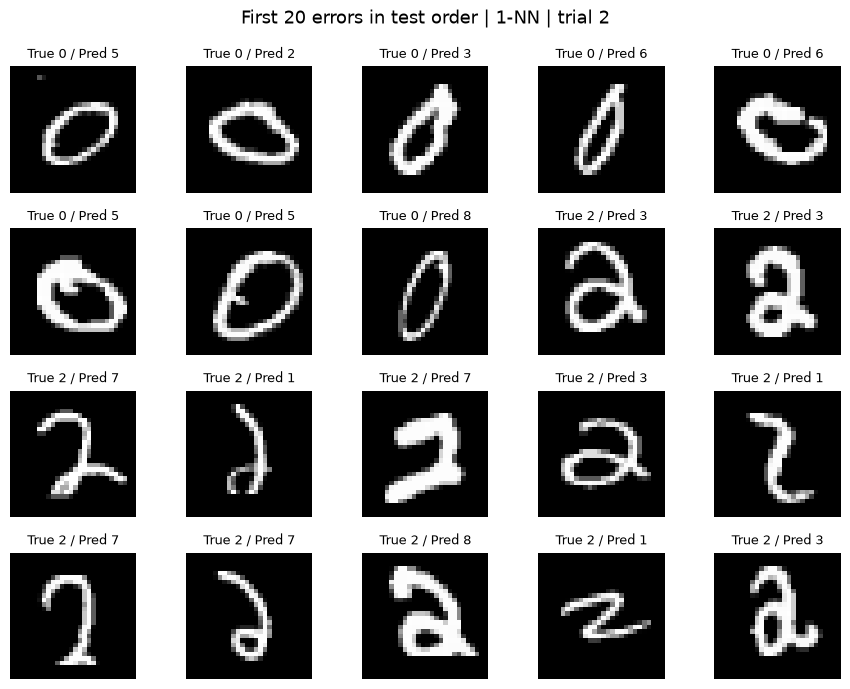

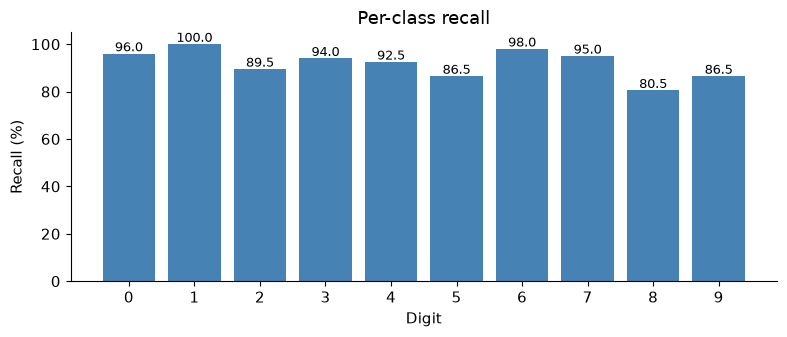

1-NN trial 2 accuracy = 0.9185


In [4]:
rows = []
for trial in [1, 2]:
    folder = output_folder("1nn", trial)
    X_train, y_train, X_test, y_test = get_trial(data, trial)
    save_json({"method": "1-NN", "n_neighbors": 1, "metric": "euclidean",
               "n_train": len(y_train), "trial": trial}, folder / "config.json")

    model = KNeighborsClassifier(n_neighbors=1, metric="euclidean", algorithm="brute", n_jobs=4)
    start = time.perf_counter()
    model.fit(X_train.reshape(-1, 784), y_train)
    train_seconds = time.perf_counter() - start

    start = time.perf_counter()
    predictions = model.predict(X_test.reshape(-1, 784))
    predict_seconds = time.perf_counter() - start
    joblib.dump(model, folder / "model.joblib")

    metrics = evaluate_predictions(
        y_test, predictions, X_test, folder, "1-NN", trial,
        train_seconds, predict_seconds, sample_indices=data["test_indices"][trial - 1])
    rows.append(metrics)

## 4. 汇总
标准差使用两个 trial 的样本标准差。比较图会自动加入其他 notebook 已保存的结果，不会据此调参。

,method,trial,n_test,accuracy,macro_f1,train_seconds,predict_seconds
0,1-NN,1,2000,0.9135,0.913031,0.042321,0.158370
1,1-NN,2,2000,0.9185,0.917932,0.003675,0.106623


,method,mean_accuracy,std_accuracy,mean_macro_f1,mean_train_seconds,mean_predict_seconds
0,1-NN,0.916,0.003536,0.915482,0.022998,0.132497


Difference from provided baseline: [0. 0.]


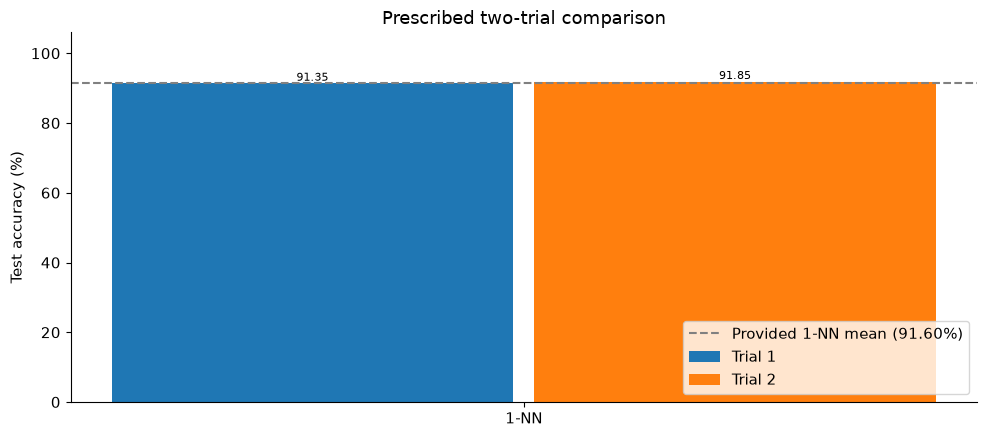

,method,mean_accuracy,std_accuracy,mean_macro_f1,mean_train_seconds,mean_predict_seconds
0,1-NN,0.916,0.003536,0.915482,0.022998,0.132497


In [5]:
display(pd.DataFrame(rows))
display(save_method_summary(rows, output_folder("1nn")))
reference = np.array([0.9135, 0.9185])
measured = np.array([row["accuracy"] for row in rows])
print("Difference from provided baseline:", measured - reference)
display(compare_methods())

## 5. 附加挑战接口（拿到数据后使用）

先按老师说明把新图像整理为 `new_images`，形状 `[N,28,28]`、亮字黑底、取值 `[0,1]`。下面只展示接口，不自动运行：

```python
model = joblib.load(output_folder("1nn", 1) / "model.joblib")
new_predictions = model.predict(new_images.reshape(-1, 784))
```

挑战最终采用哪组模型、是否允许用全部 4,000 张训练，等老师公布规则后确定。